# EDA · Relaciones entre variables y visualizaciones

**Tarea de Jira:** DSAP-8 · **Responsable:** Jorge · **Dataset:** NYC 311 (`nyc_311_safety.parquet`)

**Objetivo:** Entender cómo se relacionan las variables y producir gráficas útiles para la maqueta del tablero.

# DSAP-8 | Relaciones entre variables y visualizaciones

## Proyecto: NYC 311 Safety

### Objetivo

Explorar las relaciones entre las variables categóricas,
temporales y geográficas del conjunto de datos NYC 311.

### Metodología

1. Analizar relaciones entre categorías y subcategorías.
2. Evaluar la distribución de estados por categoría.
3. Identificar patrones temporales de las solicitudes.
4. Examinar la distribución geográfica.
5. Construir visualizaciones e interpretar los resultados.

Los análisis se realizarán sobre el dataset original,
sin modificar los datos versionados mediante DVC.

In [1]:
# DSAP-8 | Carga de datos y librerías

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configuración de las visualizaciones
sns.set_theme(style="whitegrid")

# Cargar los datos descargados mediante DVC
ruta = Path("../data/raw/nyc_311_safety.parquet")
df = pd.read_parquet(ruta)

# Confirmar las dimensiones
print(f"Registros: {df.shape[0]:,}")
print(f"Variables: {df.shape[1]}")

# Visualizar las variables disponibles
print(df.head())

Registros: 3,167,279
Variables: 11
  dataType dataSubtype            dateTime            category  \
0   Safety     311_All 2023-12-01 04:57:07      HEAT/HOT WATER   
1   Safety     311_All 2023-02-24 18:25:45     Noise - Vehicle   
2   Safety     311_All 2023-08-03 16:11:03  Vendor Enforcement   
3   Safety     311_All 2023-09-27 11:07:32     Noise - Vehicle   
4   Safety     311_All 2023-08-05 18:46:29            Drinking   

       subcategory  status                 address   latitude  longitude  \
0  ENTIRE BUILDING  Closed    269 AMSTERDAM AVENUE  40.778972 -73.981351   
1  Car/Truck Music  Closed       1146 ELDER AVENUE  40.827250 -73.878852   
2      Food Vendor  Closed  1774 VICTORY BOULEVARD  40.613050 -74.122877   
3  Car/Truck Music  Closed      2189 JEROME AVENUE  40.856739 -73.904894   
4        In Public  Closed    2545 GRAND CONCOURSE  40.863451 -73.896389   

  source extendedProperties  
0    NaN                     
1    NaN                     
2    NaN             

## 2. Relaciones entre variables

El análisis de relaciones se realizará considerando la naturaleza
estadística de cada variable.

Se utilizarán tres enfoques:

1. Correlaciones entre variables numéricas mediante Pearson y Spearman.
2. Asociaciones entre variables categóricas mediante V de Cramér.
3. Relaciones entre variables categóricas y numéricas mediante eta.

Adicionalmente, se derivarán características temporales de `dateTime`
para explorar patrones horarios, semanales y mensuales.

Las variables constantes, sin información o con cardinalidad excesiva
serán evaluadas antes de construir las matrices.

In [2]:
# DSAP-8 | Exploración de la variable status
# Objetivo: determinar si existe variabilidad suficiente
# para estudiar su relación con la categoría de solicitud.

distribucion_status = (
    df["status"]
    .value_counts(dropna=False)
    .rename_axis("Estado")
    .reset_index(name="Cantidad")
)

# Calcular el porcentaje de cada estado
distribucion_status["Porcentaje"] = (
    distribucion_status["Cantidad"] / len(df) * 100
).round(2)

display(distribucion_status)

,Estado,Cantidad,Porcentaje
0,Closed,2959895,93.45
1,In Progress,127734,4.03
2,Open,61101,1.93
3,Assigned,10807,0.34
4,Pending,4802,0.15
5,Started,1511,0.05
6,Unspecified,1429,0.05


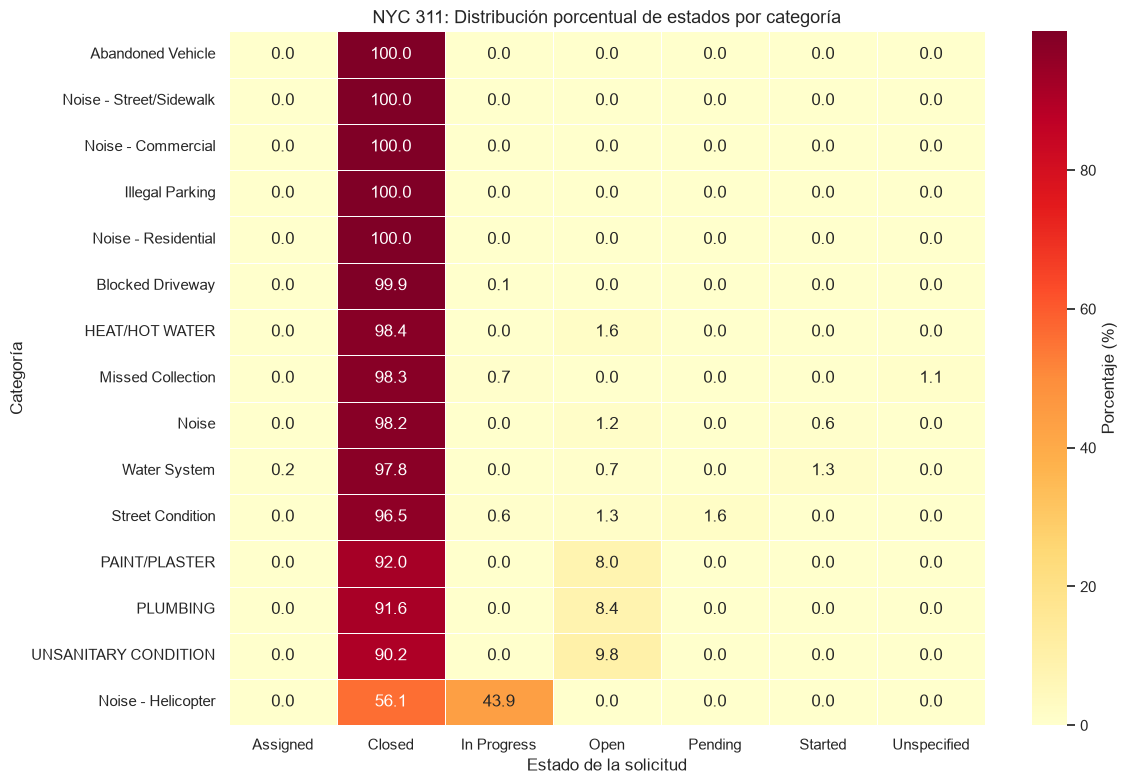

In [3]:
# DSAP-8 | Relación entre categoría y estado de la solicitud
# Objetivo: identificar qué categorías tienen mayor
# proporción de solicitudes abiertas, en proceso o pendientes.

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Seleccionar las 15 categorías más frecuentes
top_categorias = df["category"].value_counts().head(15).index

df_top = df.loc[
    df["category"].isin(top_categorias),
    ["category", "status"]
].copy()

# 2. Construir la tabla de contingencia
tabla_status = pd.crosstab(
    df_top["category"],
    df_top["status"],
    normalize="index"
) * 100

# 3. Ordenar por porcentaje de solicitudes cerradas
tabla_status = tabla_status.sort_values(
    by="Closed",
    ascending=False
)

# 4. Crear el mapa de calor
plt.figure(figsize=(12, 8))

sns.heatmap(
    tabla_status,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Porcentaje (%)"}
)

plt.title(
    "NYC 311: Distribución porcentual de estados por categoría",
    fontsize=13
)
plt.xlabel("Estado de la solicitud")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()

### Interpretación: relación entre categoría y estado

El mapa de calor muestra diferencias importantes en la
distribución de los estados según la categoría de solicitud.

**Hallazgos principales:**

1. Las categorías Abandoned Vehicle, Noise - Residential,
   Noise - Commercial e Illegal Parking presentan
   prácticamente el 100 % de solicitudes cerradas.

2. Las categorías UNSANITARY CONDITION (9,8 %),
   PLUMBING (8,4 %) y PAINT/PLASTER (8,0 %)
   presentan proporciones destacables de solicitudes abiertas.

3. Noise - Helicopter presenta el comportamiento más
   diferente: 43,9 % de solicitudes en proceso
   y 56,1 % cerradas.

**Conclusión:**

Se observan diferencias descriptivas entre la categoría
de solicitud y el estado registrado, lo que sugiere
la conveniencia de evaluar estadísticamente su asociación.

No es posible concluir que estas diferencias representen
mayores tiempos de atención sin conocer las fechas de
resolución y otras características de las solicitudes.

**Limitación:**

El análisis considera únicamente las 15 categorías
más frecuentes y los porcentajes se calculan dentro
de cada categoría.

In [4]:
# DSAP-8 | Asociación entre categoría y estado
# Técnica: V de Cramér

import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

# 1. Construir una tabla de contingencia con las 15
# categorías utilizadas en el mapa de calor.
contingencia = pd.crosstab(
    df_top["category"],
    df_top["status"]
)

# 2. Aplicar prueba de independencia chi-cuadrado.
chi2, p_valor, grados_libertad, esperados = chi2_contingency(
    contingencia
)

# 3. Calcular V de Cramér.
n = contingencia.to_numpy().sum()
filas, columnas = contingencia.shape

v_cramer = np.sqrt(
    (chi2 / n) / min(filas - 1, columnas - 1)
)

# 4. Mostrar resultados.
print("Asociación: category vs. status")
print(f"Registros analizados: {n:,}")
print(f"Chi-cuadrado: {chi2:,.2f}")
print(f"p-valor: {p_valor:.6g}")
print(f"V de Cramér: {v_cramer:.4f}")

Asociación: category vs. status
Registros analizados: 1,934,911
Chi-cuadrado: 989,021.26
p-valor: 0
V de Cramér: 0.2919


### Asociación estadística entre categoría y estado

Se evaluó la asociación entre las 15 categorías de
solicitudes más frecuentes y sus estados mediante
la prueba chi-cuadrado y el coeficiente V de Cramér.

**Resultados:**

- Registros analizados: 1.934.911.
- Chi-cuadrado: 989.021,26.
- p-valor: aproximadamente 0.
- V de Cramér: 0,2919.

**Interpretación:**

El coeficiente V de Cramér indica una asociación de
magnitud moderada, bajo criterios orientativos, entre
la categoría de solicitud y su estado.

Los resultados descriptivos muestran que algunas
categorías presentan proporciones considerablemente
mayores de solicitudes abiertas o en proceso.

Debido al elevado número de registros, se prioriza
la magnitud de la asociación sobre la significancia
estadística por sí sola.

**Limitaciones:**

- El análisis considera únicamente las 15 categorías
  más frecuentes.
- No se establece una relación causal.
- La interpretación de la prueba chi-cuadrado requiere
  verificar las frecuencias esperadas.

In [5]:
# DSAP-8 | Validación de frecuencias esperadas
# La prueba chi-cuadrado utiliza una aproximación
# que puede ser poco fiable con frecuencias muy bajas.

import numpy as np

print("Frecuencia esperada mínima:", esperados.min())
print("Celdas con frecuencia esperada < 5:", (esperados < 5).sum())
print("Porcentaje de celdas con esperada < 5:",
      round((esperados < 5).mean() * 100, 2), "%")

Frecuencia esperada mínima: 2.524028236957669
Celdas con frecuencia esperada < 5: 9
Porcentaje de celdas con esperada < 5: 8.57 %


### Validación de los supuestos de chi-cuadrado

Se evaluaron las frecuencias esperadas de la tabla de
contingencia entre categoría y estado de las solicitudes.

**Resultados:**

- Frecuencia esperada mínima: 2,52.
- Celdas con frecuencia esperada inferior a 5: 9.
- Porcentaje de celdas con frecuencia esperada inferior a 5: 8,57 %.

**Conclusión:**

La tabla cumple los criterios orientativos habituales para
aplicar la aproximación chi-cuadrado, dado que ninguna
frecuencia esperada es inferior a 1 y menos del 20 %
de las celdas presentan frecuencias esperadas inferiores a 5.

Se mantiene el resultado de V de Cramér = 0,2919,
que evidencia una asociación entre la categoría y el estado
de las solicitudes.

El análisis es descriptivo y no permite establecer
relaciones causales.

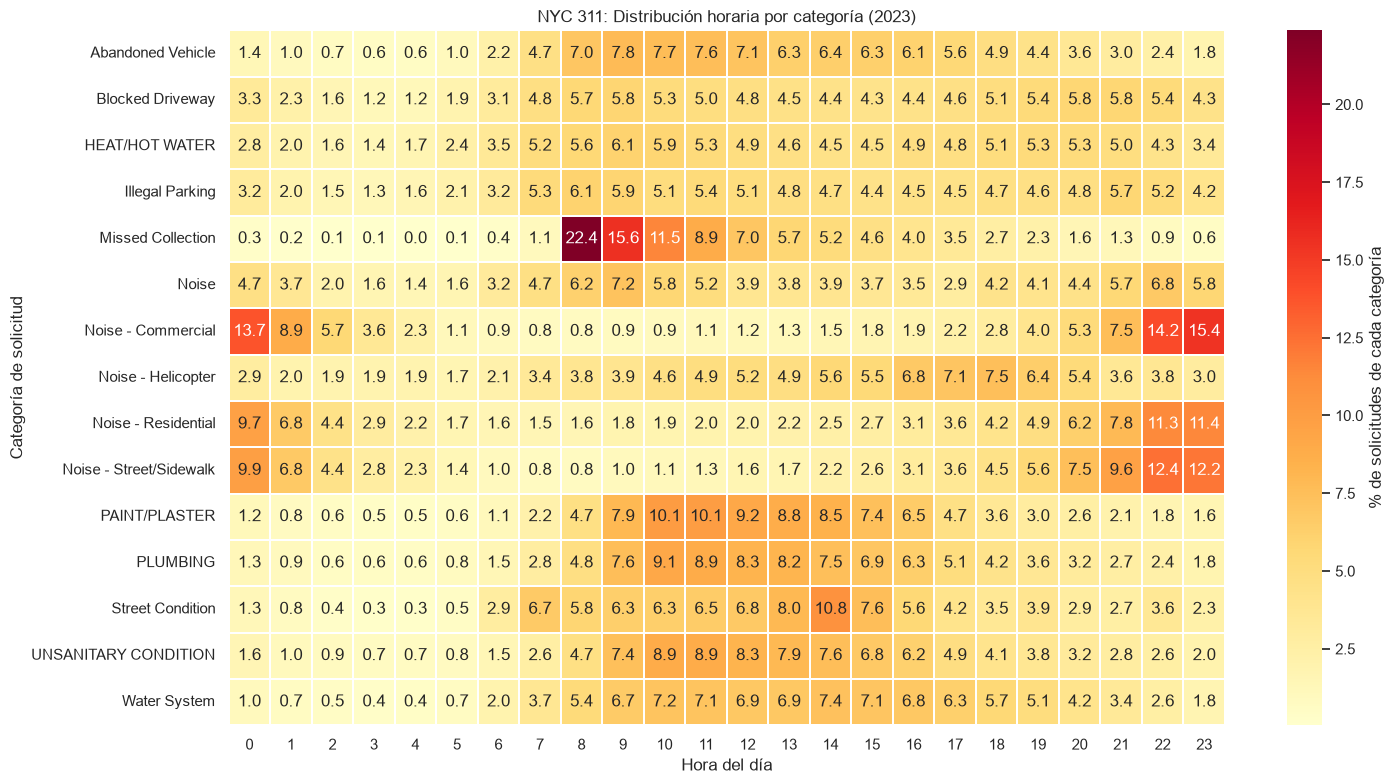

In [6]:
# DSAP-8 | Relación entre categoría y hora del día
# Objetivo: identificar patrones horarios por tipo de solicitud.

# 1. Trabajar con las 15 categorías más frecuentes
top_15 = df["category"].value_counts().head(15).index

df_horario = df.loc[
    df["category"].isin(top_15),
    ["category", "dateTime"]
].copy()

# 2. Extraer la hora del registro (0 a 23)
df_horario["hora"] = df_horario["dateTime"].dt.hour

# 3. Construir tabla de frecuencias
tabla_horaria = pd.crosstab(
    df_horario["category"],
    df_horario["hora"]
)

# 4. Normalizar por categoría para comparar patrones,
# independientemente de cuántas solicitudes tenga cada una.
tabla_horaria_pct = (
    tabla_horaria.div(tabla_horaria.sum(axis=1), axis=0) * 100
)

# 5. Visualizar el mapa de calor
plt.figure(figsize=(15, 8))

sns.heatmap(
    tabla_horaria_pct,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.2,
    cbar_kws={"label": "% de solicitudes de cada categoría"}
)

plt.title("NYC 311: Distribución horaria por categoría (2023)")
plt.xlabel("Hora del día")
plt.ylabel("Categoría de solicitud")
plt.tight_layout()
plt.show()

### Interpretación: relación entre categoría y hora del día

Se analizó la distribución porcentual de las solicitudes
de las 15 categorías más frecuentes según la hora registrada.

**Hallazgos principales:**

1. **Solicitudes de ruido:** Noise - Commercial, Noise -
   Residential y Noise - Street/Sidewalk presentan mayor
   concentración durante la noche, especialmente entre
   las 22:00 y las 00:00.

2. **Recolección de residuos:** Missed Collection presenta
   una concentración particularmente elevada a las 08:00,
   cuando se registra el 22,4 % de las solicitudes de
   esta categoría.

3. **Condiciones de vivienda:** PAINT/PLASTER y PLUMBING
   muestran mayor concentración durante el horario diurno,
   especialmente entre las 09:00 y las 14:00.

4. **Condiciones de calles:** Street Condition alcanza
   su mayor concentración a las 14:00, con un 10,8 %.

5. **Ruido de helicópteros:** Noise - Helicopter presenta
   un comportamiento diferente de las demás categorías
   de ruido, con mayor concentración hacia las 18:00.

**Conclusión:**

La distribución horaria no es uniforme entre las categorías.
Se identifican patrones diferenciados que sugieren que la
hora de registro puede ser una característica relevante
para comprender el comportamiento de las solicitudes.

Estos hallazgos aportan evidencia para evaluar variables
temporales en futuros modelos predictivos.

**Limitaciones:**

- El análisis utiliza únicamente las 15 categorías más frecuentes.
- Los porcentajes se calculan dentro de cada categoría.
- La hora de registro no necesariamente corresponde al
  momento en que ocurrió la situación reportada.
- Se deben verificar posibles efectos de procesos
  administrativos o automatizados sobre los horarios.

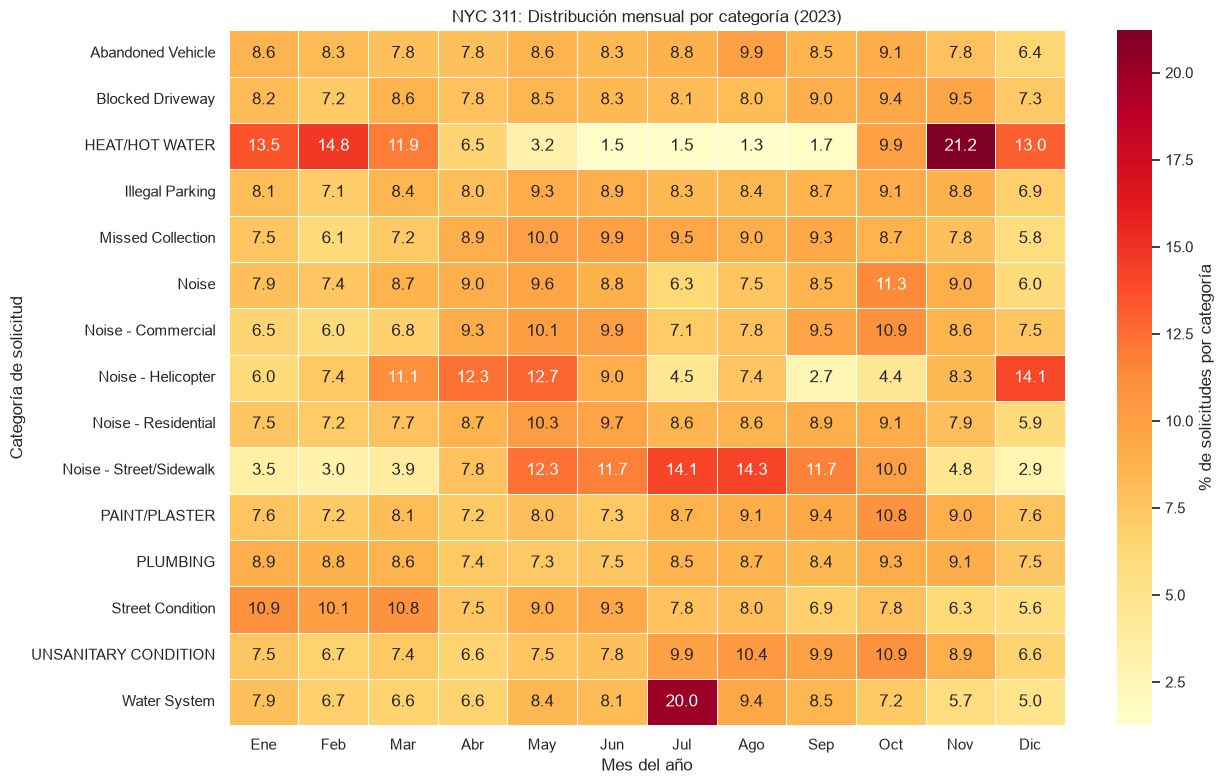

In [7]:
# DSAP-8 | Relación entre categoría y mes
# Objetivo: identificar patrones mensuales por tipo de solicitud.

# 1. Seleccionar las 15 categorías más frecuentes
top_15 = df["category"].value_counts().head(15).index

df_mensual = df.loc[
    df["category"].isin(top_15),
    ["category", "dateTime"]
].copy()

# 2. Extraer el mes de registro
df_mensual["mes"] = df_mensual["dateTime"].dt.month

# 3. Construir tabla de frecuencias
tabla_mensual = pd.crosstab(
    df_mensual["category"],
    df_mensual["mes"]
)

# 4. Calcular porcentajes dentro de cada categoría
tabla_mensual_pct = (
    tabla_mensual.div(tabla_mensual.sum(axis=1), axis=0) * 100
)

# 5. Visualizar el mapa de calor
plt.figure(figsize=(13, 8))

sns.heatmap(
    tabla_mensual_pct,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "% de solicitudes por categoría"}
)

plt.title("NYC 311: Distribución mensual por categoría (2023)")
plt.xlabel("Mes del año")
plt.ylabel("Categoría de solicitud")
plt.xticks(
    ticks=[i + 0.5 for i in range(12)],
    labels=["Ene", "Feb", "Mar", "Abr", "May", "Jun",
            "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"],
    rotation=0
)

plt.tight_layout()
plt.show()

### Interpretación: relación entre categoría y mes del año

Se analizó la distribución mensual de las 15 categorías
más frecuentes de solicitudes NYC 311 durante 2023.

**Hallazgos principales:**

1. **HEAT/HOT WATER:** presenta una concentración elevada
   en los meses fríos, especialmente noviembre (21,2 %),
   febrero (14,8 %) y enero (13,5 %).

2. **Noise - Street/Sidewalk:** muestra mayor concentración
   durante julio (14,1 %) y agosto (14,3 %), lo que sugiere
   posibles diferencias estacionales en los reportes de ruido.

3. **Water System:** presenta un pico destacado en julio
   (20,0 % de las solicitudes anuales de la categoría).
   Este comportamiento requiere un análisis específico
   para comprender su origen.

4. **Categorías más estables:** Illegal Parking,
   Blocked Driveway y PLUMBING muestran distribuciones
   mensuales relativamente más uniformes.

**Conclusión:**

La distribución temporal varía según el tipo de solicitud.
Los resultados sugieren que el mes del año puede ser una
variable relevante para describir y eventualmente
predecir el volumen de solicitudes por categoría.

**Limitaciones:**

- El conjunto de datos contiene únicamente registros de 2023.
- Diciembre termina el día 24, por lo que tiene una
  cobertura inferior a la de los demás meses.
- Los porcentajes representan la distribución anual
  dentro de cada categoría, no la participación de
  cada categoría en el total mensual.
- Los patrones observados no demuestran causalidad
  ni permiten confirmar estacionalidad recurrente
  con un solo año de información.

Registros geográficos válidos: 3,118,735
Porcentaje del dataset: 98.47%


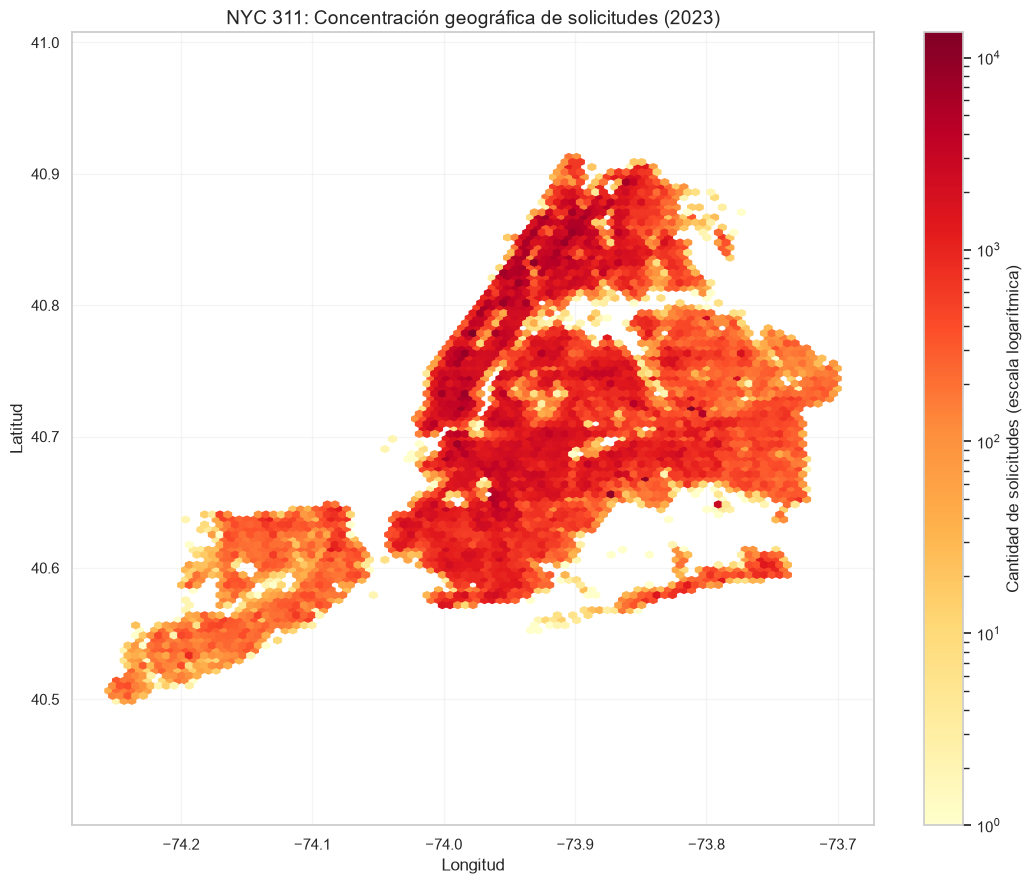

In [8]:
# DSAP-8 | Distribución geográfica de solicitudes NYC 311
# Objetivo: identificar áreas de concentración espacial.

import matplotlib.pyplot as plt
import numpy as np

# 1. Seleccionar coordenadas disponibles
df_geo = df[["latitude", "longitude"]].dropna().copy()

# 2. Validar rangos geográficos aproximados de NYC
# Esto ayuda a excluir posibles errores de coordenadas.
df_geo = df_geo[
    df_geo["latitude"].between(40.45, 40.95) &
    df_geo["longitude"].between(-74.30, -73.65)
]

# 3. Mostrar registros utilizados
print(f"Registros geográficos válidos: {len(df_geo):,}")
print(
    f"Porcentaje del dataset: "
    f"{len(df_geo) / len(df) * 100:.2f}%"
)

# 4. Crear el mapa de densidad
plt.figure(figsize=(11, 9))

hb = plt.hexbin(
    df_geo["longitude"],
    df_geo["latitude"],
    gridsize=95,
    mincnt=1,
    bins="log",
    cmap="YlOrRd"
)

plt.colorbar(
    hb,
    label="Cantidad de solicitudes (escala logarítmica)"
)

plt.title(
    "NYC 311: Concentración geográfica de solicitudes (2023)",
    fontsize=14
)
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.axis("equal")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [9]:
# DSAP-8 | Verificar disponibilidad de Folium
# Folium permite visualizar coordenadas sobre un mapa geográfico.

try:
    import folium
    print("Folium instalado correctamente")
    print("Versión:", folium.__version__)
except ImportError:
    print("Folium no está instalado")

Folium instalado correctamente
Versión: 0.20.0


In [10]:
# DSAP-8 | Instalar Folium en el entorno del notebook
# %pip instala el paquete en el entorno Python del kernel activo.

%pip install folium

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import folium

print("Folium instalado correctamente")
print("Versión:", folium.__version__)

Folium instalado correctamente
Versión: 0.20.0


In [12]:
# DSAP-8 | Mapa interactivo de solicitudes NYC 311
# Objetivo: visualizar su ubicación sobre un mapa real.

import folium
from folium.plugins import FastMarkerCluster

# 1. Seleccionar registros con coordenadas válidas
df_mapa = df[
    df["latitude"].between(40.45, 40.95) &
    df["longitude"].between(-74.30, -73.65)
].dropna(subset=["latitude", "longitude"])

# 2. Seleccionar una muestra reproducible de 5.000 solicitudes
# para evitar sobrecargar el mapa interactivo.
muestra_mapa = df_mapa.sample(
    n=min(5000, len(df_mapa)),
    random_state=42
)

# 3. Crear el mapa centrado en Nueva York
mapa_nyc = folium.Map(
    location=[40.73, -73.94],
    zoom_start=11,
    tiles="OpenStreetMap"
)

# 4. Agregar los puntos geográficos agrupados
coordenadas = muestra_mapa[
    ["latitude", "longitude"]
].values.tolist()

FastMarkerCluster(coordenadas).add_to(mapa_nyc)

# 5. Guardar el mapa interactivo como evidencia
mapa_nyc.save("mapa_nyc_311.html")

print(f"Solicitudes representadas: {len(muestra_mapa):,}")
print("Mapa guardado: mapa_nyc_311.html")

# 6. Mostrar el mapa en Jupyter
display(mapa_nyc)

Solicitudes representadas: 5,000
Mapa guardado: mapa_nyc_311.html


In [13]:
# DSAP-8 | Corregir el mapa base interactivo
# Reutilizamos las coordenadas ya preparadas.

import folium
from folium.plugins import FastMarkerCluster

mapa_nyc = folium.Map(
    location=[40.73, -73.94],
    zoom_start=11,
    tiles="CartoDB positron"
)

# Agregar los mismos 5.000 puntos
FastMarkerCluster(coordenadas).add_to(mapa_nyc)

# Guardar la versión corregida
mapa_nyc.save("mapa_nyc_311_corregido.html")

# Visualizar dentro del notebook
display(mapa_nyc)

c:\Users\georg\Documents\Uniandes\DSA\dsa-proyecto\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [14]:
# DSAP-8 | Mapa interactivo con base cartográfica de Esri
# Reutilizamos los 5.000 puntos que ya seleccionamos.

import folium
from folium.plugins import FastMarkerCluster

mapa_esri = folium.Map(
    location=[40.73, -73.94],
    zoom_start=11,
    tiles=None
)

# Añadir mapa de calles y lugares
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, HERE, Garmin, USGS y otros proveedores",
    name="Calles de Nueva York"
).add_to(mapa_esri)

# Agregar las solicitudes
FastMarkerCluster(coordenadas).add_to(mapa_esri)

# Guardar nueva versión
mapa_esri.save("mapa_nyc_311_esri.html")

print("Mapa guardado: mapa_nyc_311_esri.html")
print(f"Solicitudes representadas: {len(coordenadas):,}")

Mapa guardado: mapa_nyc_311_esri.html
Solicitudes representadas: 5,000


In [15]:
# DSAP-8 | Instalar GeoPandas
# Permite trabajar con información geográfica en Jupyter.

%pip install geopandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
# DSAP-8 | Preparación del análisis geográfico

import geopandas as gpd
import matplotlib.pyplot as plt

# Seleccionar solicitudes con coordenadas disponibles
df_geo = df[
    df["latitude"].between(40.45, 40.95) &
    df["longitude"].between(-74.30, -73.65)
].dropna(subset=["latitude", "longitude"]).copy()

# Convertir las coordenadas en puntos geográficos
gdf_nyc = gpd.GeoDataFrame(
    df_geo,
    geometry=gpd.points_from_xy(
        df_geo["longitude"],
        df_geo["latitude"]
    ),
    crs="EPSG:4326"
)

print("GeoPandas:", gpd.__version__)
print(f"Solicitudes georreferenciadas: {len(gdf_nyc):,}")
print(f"Porcentaje del dataset: {len(gdf_nyc) / len(df) * 100:.2f}%")

GeoPandas: 1.2.0
Solicitudes georreferenciadas: 3,118,735
Porcentaje del dataset: 98.47%


In [17]:
# DSAP-8 | Cargar límites geográficos de Nueva York
# Fuente: NYC Open Data - Borough Boundaries

import geopandas as gpd
from pathlib import Path

# 1. Dirección del archivo geográfico oficial
url = (
    "https://data.cityofnewyork.us/api/v3/views/"
    "gthc-hcne/query.geojson?accessType=DOWNLOAD"
)

# 2. Crear carpeta para datos geográficos auxiliares
ruta_geo = Path("../data/geo")
ruta_geo.mkdir(parents=True, exist_ok=True)

archivo_geo = ruta_geo / "nyc_boroughs.geojson"

# 3. Descargar una sola vez y conservar la copia local
if not archivo_geo.exists():
    import requests

    respuesta = requests.get(url, timeout=60)
    respuesta.raise_for_status()
    archivo_geo.write_bytes(respuesta.content)

# 4. Leer los límites con GeoPandas
boroughs = gpd.read_file(archivo_geo)

# 5. Verificar los distritos disponibles
print("Distritos encontrados:", len(boroughs))
print("Sistema de coordenadas:", boroughs.crs)

display(boroughs[["boroname"]])

Distritos encontrados: 5
Sistema de coordenadas: EPSG:4326


,boroname
0,Staten Island
1,Brooklyn
2,Queens
3,Manhattan
4,Bronx


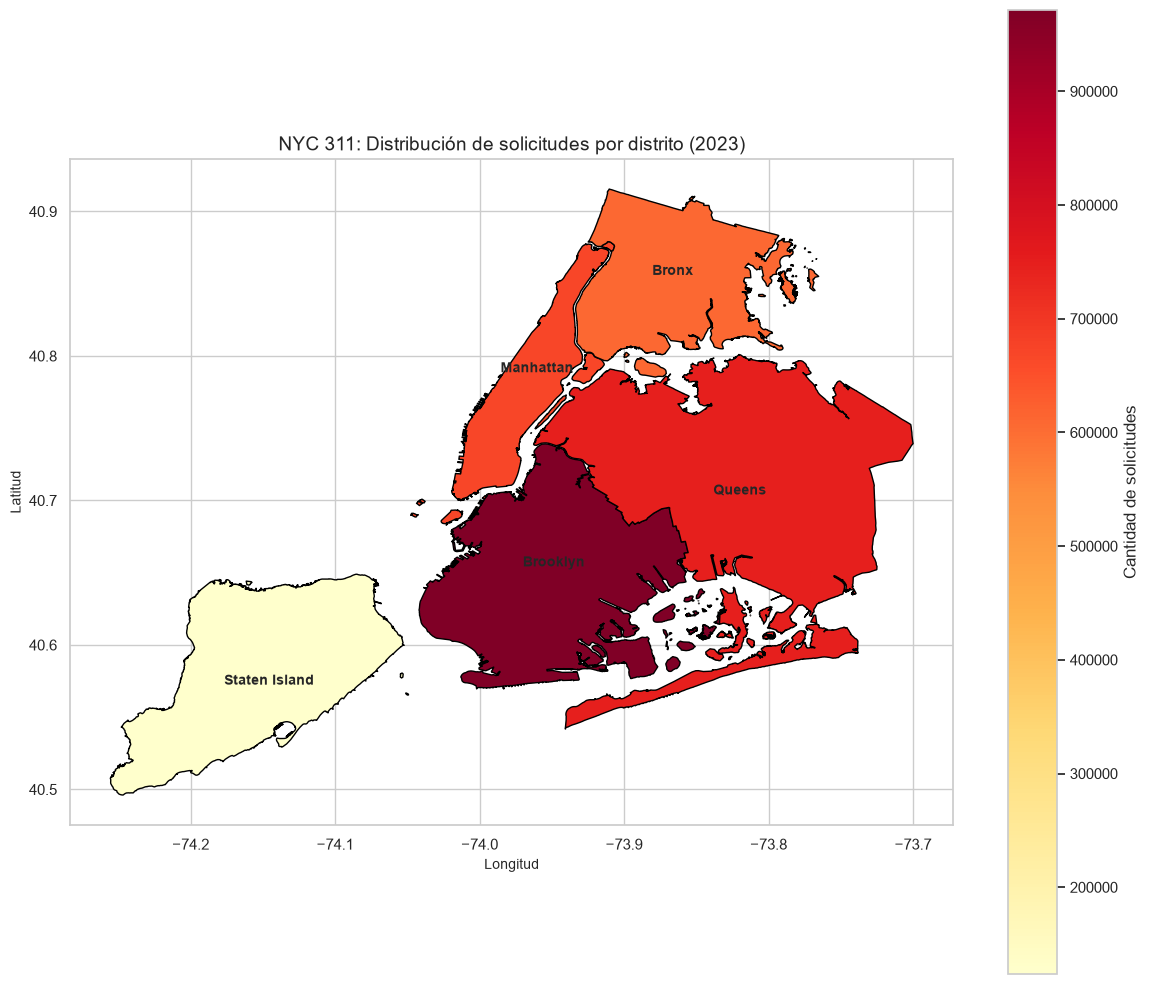

,boroname,solicitudes,porcentaje
0,Brooklyn,971516,30.67
1,Queens,747047,23.59
2,Manhattan,668343,21.10
3,Bronx,607511,19.18
4,Staten Island,123669,3.90


In [18]:
# DSAP-8 | Distribución geográfica de solicitudes por distrito
# Objetivo: relacionar la ubicación geográfica con la cantidad
# de solicitudes ciudadanas registradas durante 2023.

import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Conservar solamente las columnas necesarias
puntos = gdf_nyc[["geometry"]].copy()

# 2. Asignar cada solicitud al distrito donde se encuentra
solicitudes_distrito = gpd.sjoin(
    puntos,
    boroughs[["boroname", "geometry"]],
    how="left",
    predicate="within"
)

# 3. Contar las solicitudes por distrito
conteo = (
    solicitudes_distrito["boroname"]
    .value_counts()
    .rename_axis("boroname")
    .reset_index(name="solicitudes")
)

# 4. Incorporar los resultados al mapa geográfico
mapa_distritos = boroughs.merge(
    conteo,
    on="boroname",
    how="left"
)

mapa_distritos["solicitudes"] = (
    mapa_distritos["solicitudes"].fillna(0)
)

# 5. Dibujar el mapa
fig, ax = plt.subplots(figsize=(12, 10))

mapa_distritos.plot(
    column="solicitudes",
    cmap="YlOrRd",
    legend=True,
    edgecolor="black",
    linewidth=1,
    ax=ax,
    legend_kwds={"label": "Cantidad de solicitudes"}
)

# 6. Agregar nombres de los distritos
for _, distrito in mapa_distritos.iterrows():
    centro = distrito.geometry.representative_point()

    ax.annotate(
        text=distrito["boroname"],
        xy=(centro.x, centro.y),
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "NYC 311: Distribución de solicitudes por distrito (2023)",
    fontsize=14
)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

# 7. Mostrar cantidades y porcentajes
conteo["porcentaje"] = (
    conteo["solicitudes"] / len(df) * 100
).round(2)

display(conteo)

### Interpretación: distribución de solicitudes por distrito

Se realizó una unión espacial entre las coordenadas de
las solicitudes NYC 311 y los límites geográficos de
los cinco distritos de Nueva York.

**Hallazgos principales:**

1. Brooklyn presenta la mayor cantidad de solicitudes
   registradas en el conjunto de datos.

2. Queens también concentra una cantidad elevada de
   solicitudes, aunque inferior a Brooklyn.

3. Manhattan y Bronx presentan cantidades intermedias,
   cuya comparación exacta requiere revisar los conteos.

4. Staten Island registra la menor cantidad de solicitudes.

**Conclusión:**

La cantidad de solicitudes NYC 311 varía entre los
distritos de Nueva York, lo que evidencia una
distribución geográfica heterogénea.

**Limitaciones:**

- Se representan cantidades absolutas y no tasas
  ajustadas por población.
- Los registros sin coordenadas válidas no se incluyen.
- No se pueden interpretar los resultados como niveles
  de criminalidad o inseguridad.
- La distribución puede estar influenciada por la
  población y el uso de los canales de reporte.

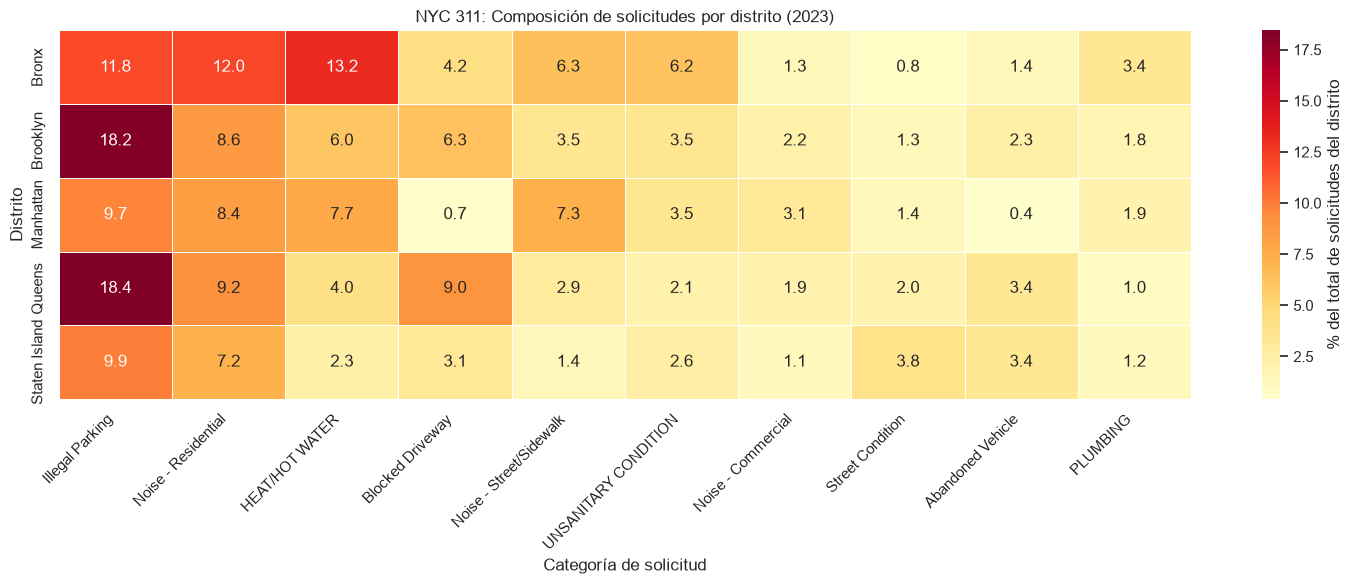

In [19]:
# DSAP-8 | Relación entre distrito y categoría
# Objetivo: comparar la composición de solicitudes por distrito.

# Incorporar la categoría de cada solicitud
puntos_categoria = gdf_nyc[["category", "geometry"]].copy()

# Asignar distrito mediante unión espacial
geo_categoria = gpd.sjoin(
    puntos_categoria,
    boroughs[["boroname", "geometry"]],
    how="inner",
    predicate="within"
)

# Seleccionar las 10 categorías más frecuentes
top_10 = df["category"].value_counts().head(10).index

# Construir tabla de contingencia con todas las categorías
tabla_distritos = pd.crosstab(
    geo_categoria["boroname"],
    geo_categoria["category"],
    normalize="index"
) * 100

# Mostrar las 10 categorías seleccionadas
tabla_distritos = tabla_distritos.reindex(
    columns=top_10,
    fill_value=0
)

# Crear mapa de calor
plt.figure(figsize=(15, 6))

sns.heatmap(
    tabla_distritos,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "% del total de solicitudes del distrito"}
)

plt.title("NYC 311: Composición de solicitudes por distrito (2023)")
plt.xlabel("Categoría de solicitud")
plt.ylabel("Distrito")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Interpretación: relación entre distrito y categoría de solicitud

Se construyó un mapa de calor para comparar la composición
porcentual de las solicitudes NYC 311 entre los cinco
distritos de Nueva York durante 2023.

**Hallazgos principales:**

1. **Estacionamiento ilegal:** Queens (18,4 %) y Brooklyn
   (18,2 %) presentan las mayores proporciones de
   solicitudes de esta categoría.

2. **Calefacción y agua caliente:** Bronx presenta la
   mayor proporción de solicitudes HEAT/HOT WATER
   (13,2 %), mientras Staten Island registra 2,3 %.

3. **Ruido residencial:** Bronx presenta la mayor
   participación (12,0 %), seguido de Queens (9,2 %).

4. **Accesos vehiculares bloqueados:** Queens presenta
   la mayor proporción (9,0 %), frente a solamente
   0,7 % en Manhattan.

5. **Condiciones de las calles:** Staten Island
   presenta la mayor proporción (3,8 %).

**Conclusión:**

La composición de solicitudes ciudadanas varía entre
los distritos de Nueva York, lo que indica diferencias
descriptivas en los tipos de situaciones reportadas.

El distrito geográfico podría ser una variable
explicativa relevante en futuros modelos predictivos.

**Limitaciones:**

- Los porcentajes corresponden al total de solicitudes
  de cada distrito, no al total de cada categoría.
- Se visualizaron únicamente las 10 categorías más
  frecuentes del conjunto de datos.
- Los registros sin ubicación geográfica válida
  quedaron excluidos.
- Las diferencias no implican causalidad ni permiten
  establecer niveles de inseguridad.

In [20]:
# DSAP-8 | Asociación entre distrito y categoría
# Objetivo: cuantificar la asociación entre dos variables categóricas.

import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

# 1. Construir la tabla de contingencia
# Utilizamos las 10 categorías mostradas en el mapa de calor.
datos_asociacion = geo_categoria.loc[
    geo_categoria["category"].isin(top_10),
    ["boroname", "category"]
].dropna()

tabla_contingencia = pd.crosstab(
    datos_asociacion["boroname"],
    datos_asociacion["category"]
)

# 2. Aplicar la prueba chi-cuadrado
chi2, p_valor, gl, frecuencias_esperadas = chi2_contingency(
    tabla_contingencia
)

# 3. Calcular V de Cramér
n = tabla_contingencia.to_numpy().sum()
filas, columnas = tabla_contingencia.shape

v_cramer = np.sqrt(
    chi2 / (n * min(filas - 1, columnas - 1))
)

# 4. Validar las frecuencias esperadas
min_esperada = frecuencias_esperadas.min()
pct_menores_5 = (frecuencias_esperadas < 5).mean() * 100

# 5. Mostrar resultados
print("ASOCIACIÓN ENTRE DISTRITO Y CATEGORÍA")
print("-" * 45)
print(f"Registros analizados: {n:,}")
print(f"Chi-cuadrado: {chi2:,.2f}")
print(f"Grados de libertad: {gl}")
print(f"p-valor: {p_valor:.6g}")
print(f"V de Cramér: {v_cramer:.4f}")
print(f"Frecuencia esperada mínima: {min_esperada:.2f}")
print(f"Celdas con esperada < 5: {pct_menores_5:.2f}%")

ASOCIACIÓN ENTRE DISTRITO Y CATEGORÍA
---------------------------------------------
Registros analizados: 1,633,088
Chi-cuadrado: 200,864.44
Grados de libertad: 36
p-valor: 0
V de Cramér: 0.1754
Frecuencia esperada mínima: 1267.62
Celdas con esperada < 5: 0.00%


### Asociación estadística entre distrito y categoría

Se evaluó la relación entre los cinco distritos de Nueva York
y las diez categorías de solicitudes más frecuentes mediante
la prueba chi-cuadrado y el coeficiente V de Cramér.

**Resultados:**

- Registros analizados: 1.633.088.
- Chi-cuadrado: 200.864,44.
- Grados de libertad: 36.
- p-valor: aproximadamente 0.
- V de Cramér: 0,1754.
- Frecuencia esperada mínima: 1.267,62.
- Celdas con frecuencia esperada inferior a 5: 0 %.

**Interpretación:**

Se rechaza la hipótesis de independencia entre el distrito
y la categoría de solicitud al nivel de significancia del 5 %.

Sin embargo, el valor de V de Cramér (0,1754) indica
una asociación de magnitud relativamente débil.

Esto significa que existen diferencias en la composición
de las solicitudes entre los distritos, pero la ubicación
geográfica por sí sola no explica completamente el tipo
de solicitud registrada.

**Conclusión para el proyecto:**

El distrito puede considerarse una variable explicativa
potencialmente útil en futuros modelos predictivos,
especialmente en combinación con características
temporales y otras variables del dataset.

**Limitaciones:**

- El análisis considera únicamente las diez categorías
  más frecuentes.
- Los registros sin ubicación válida fueron excluidos.
- La significancia estadística no implica causalidad.
- No se evaluó todavía la capacidad predictiva de
  la variable geográfica.

## 7. Conclusiones generales

El análisis exploratorio de relaciones entre variables del
dataset NYC 311 Safety permitió identificar diferencias
en los patrones temporales, categóricos y geográficos de
las solicitudes ciudadanas registradas durante 2023.

### Principales hallazgos

**1. Categoría y estado de las solicitudes**

Se identificó una asociación estadísticamente significativa
entre la categoría y el estado de las solicitudes
(V de Cramér = 0,2919).

Algunas categorías presentan una mayor proporción de
solicitudes abiertas o en proceso, aunque estas diferencias
no permiten establecer conclusiones sobre la eficiencia
de atención de las entidades.

**2. Patrones horarios**

Las solicitudes relacionadas con ruido comercial,
residencial y en espacios públicos presentan una mayor
concentración durante las horas nocturnas.

Otras categorías, como PLUMBING y PAINT/PLASTER,
presentan mayor concentración durante el día.

**3. Patrones mensuales**

Se observaron diferencias importantes en la distribución
mensual de las solicitudes.

HEAT/HOT WATER presenta una concentración elevada
en los meses fríos, mientras que Noise - Street/Sidewalk
presenta mayores porcentajes durante el verano.

Estos resultados sugieren patrones temporales relevantes,
aunque la disponibilidad de un único año impide confirmar
estacionalidad recurrente.

**4. Distribución geográfica**

La cantidad y composición de las solicitudes varía
entre los cinco distritos de Nueva York.

Brooklyn registra la mayor cantidad absoluta de
solicitudes, mientras que Staten Island presenta la menor.

**5. Asociación entre distrito y categoría**

Se identificó una asociación estadísticamente significativa,
pero relativamente débil, entre distrito y categoría
(V de Cramér = 0,1754).

Esto indica que la ubicación geográfica aporta información,
pero no explica por sí sola el tipo de solicitud.

### Implicaciones para el proyecto

Los resultados sugieren que las variables temporales,
geográficas y categóricas pueden aportar información
para desarrollar modelos supervisados de Machine Learning.

Una alternativa futura es modelar el volumen de solicitudes
por zona y período, utilizando características temporales
y antecedentes históricos.

No obstante, la viabilidad predictiva deberá evaluarse
con técnicas de validación temporal y métricas apropiadas.

### Limitaciones generales

- El dataset comprende únicamente el año 2023.
- La cobertura termina el 24 de diciembre.
- Los registros sin coordenadas válidas se excluyeron
  de los análisis espaciales.
- Los resultados son descriptivos y no demuestran causalidad.
- Las solicitudes 311 no representan necesariamente delitos.
- No se han construido ni evaluado modelos predictivos.

### Conclusión final

Las relaciones identificadas evidencian que el comportamiento
de las solicitudes NYC 311 presenta diferencias por categoría,
momento de registro y ubicación geográfica.

Los resultados proporcionan una base analítica para continuar
con la preparación de datos, selección de variables y
desarrollo de soluciones predictivas del proyecto DSA.